# Lane Keeping Assist: video analysis

## What this notebook does
This is the **perception part** of a Lane Keeping Assist system, run offline on a forward-facing road video (no vehicle control). For every frame it:
- finds the **left and right boundary of the car's own lane**,
- computes the **lane centre** and where the car sits relative to it (centred, shifted left or right, near a boundary),
- shows a **confidence score** for each boundary and marks a boundary `UNCERTAIN` when it was not detected,
- saves everything as an **annotated video**.

## Stage by stage

| Stage | What happens | Main tools |
|---|---|---|
| **Lane-paint mask** (section 2) | Keeps only the pixels that look like yellow or white paint. Yellow is found by colour, white by being brighter than the road around it. | OpenCV: HLS conversion, blur, Otsu thresholds. NumPy: boolean masks. |
| **Automatic bird's-eye transform** (section 3) | Finds the car's lane in the first second and turns the road into a top view where lane lines are parallel. No points are picked by hand. | NumPy: random sampling (RANSAC), least-squares line fit. OpenCV: perspective transform. |
| **Boundary fit and tracking** (section 4) | Looks for paint only near the previous boundary, fits a parabola to it, rejects impossible lane widths and smooths over time. | NumPy: polynomial fit. |
| **Car position** (section 5) | Compares the camera centre with the lane centre, as a fraction of the lane width. | NumPy. |
| **Overlay** (section 6) | Draws both boundaries, the centre line and the status text on the original frame. | OpenCV: polylines, putText, perspective warp. |
| **Run and review** (sections 7 to 9) | Processes the whole video, saves it, shows the pipeline stages on one frame and discusses where the system works. | OpenCV: VideoWriter. Matplotlib: figure. |

## Key concepts used

| Concept | Meaning in one line |
|---|---|
| **HLS colour space** | Describes a pixel by hue, lightness and saturation, so colour and brightness can be tested separately. |
| **Otsu threshold** | Chooses a brightness cut-off automatically from the image histogram, so it adapts to the lighting. |
| **RANSAC** | Finds a line in noisy points by trying many random lines and keeping the one most points agree with. |
| **Bird's-eye view (perspective transform)** | Re-projects the road as seen from above, so lane lines become parallel and measurable. |
| **Least-squares polynomial fit** | Finds the curve `x = a*y² + b*y + c` that passes closest to a set of points. |
| **Exponential smoothing** | Mixes a small part of the new estimate into the old one, so the overlay does not jitter. |

## What the overlay shows
Left boundary **red**, right boundary **blue**, lane centre **white**. A boundary that was not detected is drawn **grey** and labelled `UNCERTAIN`. The position label turns orange in that case.

## 1. Load the video

This cell imports the libraries and opens the video file. It then reads three numbers **from the file itself**: the frame width, the frame height and the frame rate. Every later size (blur width, search margin, line thickness, text size, lane width in the top view) is computed from them, so the notebook works on any resolution without editing. `VIDEO_PATH` is the input video and `OUTPUT_PATH` is where the annotated video will be written in section 7.

In [1]:
import cv2                            
import numpy as np                   
import matplotlib.pyplot as plt      

VIDEO_PATH = "nD_11.mp4"      
OUTPUT_PATH = "NORMAL_road.mp4"       

video = cv2.VideoCapture(VIDEO_PATH)

# size and frame rate come from the file, so every later size scales with the video
frame_width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = video.get(cv2.CAP_PROP_FPS) or 25     # 25 if the file does not report a frame rate

## 2. Lane-marking mask
**Goal:** turn a frame into a True/False image that is `True` on lane paint.

| Parameter | Value | Why |
|---|---|---|
| `BLUR_WIDTH` | 1/16 of the frame width | Much wider than a marking, so the blur measures the road around the marking, not the marking itself. |

### 2.1 Automatic threshold

Lane paint is brighter or more colourful than asphalt, but how much brighter depends on sun, shade and camera exposure. A fixed threshold would work in one place and fail in another. This small function uses **Otsu's method**: it looks at the histogram of a channel (how many pixels have each value) and picks the cut-off that best separates the dark group from the bright group. The mask calls it on every frame, so the thresholds follow the lighting.

In [2]:
def otsu_threshold(channel):
    # Otsu: picks the cut-off that best separates dark and bright pixels, using only the histogram
    threshold, _ = cv2.threshold(channel, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return threshold

### 2.2 Yellow and white paint

This cell builds the mask. The two paint colours are detected in different ways. **Yellow** is recognised by colour: the hue must be close to yellow and the colour must be vivid (high saturation). **White** has no colour to look for, so it is recognised by brightness: a pixel counts as white paint when it is brighter than the average of its own row, like a stripe on darker asphalt, *and* bright in absolute terms. The first test finds faint dashes, the second ignores bright but plain surfaces such as concrete. The result is `True` where there is paint.

In [3]:
BLUR_WIDTH = int(frame_width / 16) | 1     # odd kernel width, much wider than a marking

def lane_marking_mask(bgr_image):
    # HLS separates colour (hue) from brightness (lightness), so paint stays recognisable in shade
    hue, lightness, saturation = cv2.split(cv2.cvtColor(bgr_image, cv2.COLOR_BGR2HLS))

    # average lightness around each pixel along its row: paint is a local peak above it
    row_average = cv2.blur(lightness, (BLUR_WIDTH, 1))
    # int16 lets the subtraction go negative; uint8 would wrap around to a large number
    brighter_than_row = np.clip(lightness.astype(np.int16) - row_average, 0, 255).astype(np.uint8)

    # yellow paint: hue close to 30 (OpenCV stores hue as degrees / 2, yellow is 60 degrees) and a vivid colour
    is_yellow = (abs(hue.astype(int) - 30) <= 10) & (saturation > otsu_threshold(saturation))

    # white paint: brighter than its row AND bright overall
    is_white = (brighter_than_row > otsu_threshold(brighter_than_row)) & (lightness > otsu_threshold(lightness))

    return is_yellow | is_white

## 3. Automatic bird's-eye transform
**Goal:** a top view in which the lane lines are parallel. The 4 source points are found automatically, not picked by hand.

| Parameter | Value | Why |
|---|---|---|
| `ROAD_TOP_ROW` | 60 % of the height | The road is below the horizon; sky, trees and barriers above only add noise. |
| `PAINT_WIDTH_PX` | 1 % of the width | A pixel belongs to a line if it is this close to it (about the width of the paint). |
| `RANSAC_ITERATIONS` | from a formula | 99 % chance to find a line that holds at least 20 % of the paint pixels. |
| `LANE_WIDTH_PX` | half of the width | In the top view the lane fills the middle half of the image. |

### 3.1 Collect paint pixels

Calibration needs the positions of the lane lines, so this function gathers every paint pixel from the road part of each frame it is given (the lower 40 % of the image, below the horizon). It returns one list of `(x, y)` points. It is called on **one second of video** rather than a single frame because dashed lines move along the road: a single frame shows only some dashes, while a second of frames together traces the whole line.

In [4]:
ROAD_TOP_ROW = int(0.6 * frame_height)        # first image row of the road region

def collect_paint_points(frames):
    points = []
    for frame in frames:
        road = frame[ROAD_TOP_ROW:]                            # ignore sky, trees and barriers above the road
        rows, cols = np.nonzero(lane_marking_mask(road))       # positions of paint pixels inside the crop
        points.append(np.c_[cols, rows + ROAD_TOP_ROW])        # (x, y), shifted back to full-frame coordinates
    return np.vstack(points).astype(float)

### 3.2 Find the strongest line (RANSAC)

The paint points are noisy: they include dashes, the neighbouring lanes and a few false pixels. **RANSAC** finds the dominant straight line anyway. It repeats this many times: pick two random points, draw the line through them, count the points that lie within a paint width of that line. The line with the most supporters wins, and stray pixels cannot pull it away. The number of tries is computed so that, with 99 % probability, at least one pair lands on a line holding 20 % of the points.

In [5]:
PAINT_WIDTH_PX = 0.01 * frame_width     # a pixel is "on a line" if it is within this distance
RANSAC_ITERATIONS = int(np.log(1 - 0.99) / np.log(1 - 0.2 ** 2)) + 1
random_generator = np.random.default_rng(0)   

def find_strongest_line(points):
    best_inliers = None
    for _ in range(RANSAC_ITERATIONS):
        (x1, y1), (x2, y2) = points[random_generator.choice(len(points), 2, replace=False)]
        
        if y1 == y2:                                    
            continue
        slope = (x2 - x1) / (y2 - y1)                  
        intercept = x1 - slope * y1                    

        # inliers = points whose horizontal distance to the candidate line is under one paint width
        inliers = abs(points[:, 0] - (slope * points[:, 1] + intercept)) < PAINT_WIDTH_PX

        # keep the candidate with the most inliers so far: the strongest line wins
        if best_inliers is None or inliers.sum() > best_inliers.sum():
            best_inliers = inliers
    return best_inliers

### 3.3 Collect the strongest lines of one side

One RANSAC run returns only the single strongest line, but the road has several: the car's own boundary, the neighbouring lane's boundary and so on. This function repeats the search up to four times on one side of the image. After each find it refines the line with a least-squares fit on its supporters, stores it with its **support** (how many pixels back it) and the lowest row where it is seen, then **removes its pixels** so the next run finds the next line. Left and right are searched separately by keeping only the paint on that side of the image centre.

In [6]:
from collections import namedtuple

LINES_PER_SIDE = 4                                                                    # how many lines are searched on each side
Line = namedtuple("Line", "slope intercept bottom_row support")                       # x = slope * y + intercept

def find_side_lines(paint_points, side):
    # only the paint on this side of the image centre
    side_points = paint_points[(paint_points[:, 0] - frame_width / 2) * side > 0]
    lines = []
    for _ in range(LINES_PER_SIDE):
        if len(side_points) < 2:                                                      # a line needs at least 2 points
            break
        inliers = find_strongest_line(side_points)
        if inliers is None:                                                           # no valid line left on this side
            break

        # least squares on all supporters gives a more exact line than the two random points
        #supporting points to find the line that minimizes the sum of squared errors.
        slope, intercept = np.polyfit(side_points[inliers, 1], side_points[inliers, 0], 1)
        bottom_row = np.percentile(side_points[inliers, 1], 95)                       # lowest row where the line is seen 
        lines.append(Line(slope, intercept, bottom_row, inliers.sum()))

        side_points = side_points[~inliers]                                           # remove this line's pixels, then search the next one
    return lines

### 3.4 Pick the car's own lane and build the trapezoid

Now there are several candidate lines per side, and the system must decide which two bound the car's own lane. First it drops weak candidates (less than half the support of the strongest). Then on each side it takes the line **closest to the car** at the bottom of the image: that is the boundary of the lane the car is in, not of the next one. The two chosen lines meet at the **vanishing point**, which gives the horizon row. The function returns a trapezoid between the two lines, from the lowest row where both are seen up to halfway to the horizon. This is the patch of road that will be stretched into a rectangle in the next cell.

In [7]:
def find_lane_trapezoid(frames):
    paint_points = collect_paint_points(frames)
    side_lines = {side: find_side_lines(paint_points, side) for side in (-1, 1)}

    # keep only strong lines on each side (at least half the support of the strongest)
    for side, lines in side_lines.items():
        strongest = max(line.support for line in lines)
        side_lines[side] = [line for line in lines if line.support >= 0.5 * strongest]

    # the line closest to the car at the bottom row is the car's own lane boundary
    def distance_to_car(line):
        return abs(line.slope * frame_height + line.intercept - frame_width / 2)
    left_line = min(side_lines[-1], key=distance_to_car)
    right_line = min(side_lines[1], key=distance_to_car)

    # vanishing point: the row where the two lines cross (slope_l*y + int_l = slope_r*y + int_r)
    horizon_row = (right_line.intercept - left_line.intercept) / (left_line.slope - right_line.slope)
    bottom_row = min(left_line.bottom_row, right_line.bottom_row)           # lowest row where both lines are seen
    top_row = horizon_row + (bottom_row - horizon_row) / 2                  # halfway to the horizon: the top view is still sharp there

    def x_on(line, row):
        return line.slope * row + line.intercept

    # corners: bottom-left, top-left, top-right, bottom-right
    trapezoid = np.float32([(x_on(left_line, bottom_row), bottom_row), (x_on(left_line, top_row), top_row),
                            (x_on(right_line, top_row), top_row), (x_on(right_line, bottom_row), bottom_row)])
    return trapezoid, bottom_row

### 3.5 Run the calibration and build the transform

This cell runs the calibration on the first second of the video and builds the two **perspective transforms**. The trapezoid found above is mapped to a rectangle that fills the middle half of the image, so in the top view the lane is `LANE_WIDTH_PX` wide and both lines are vertical and parallel. `to_birdseye` converts a camera frame to that top view. `from_birdseye` is its inverse and is used later to draw the results back onto the original frame. The transform is computed **once** and reused for the whole video.

In [8]:
first_second = [video.read()[1] for _ in range(int(fps))]                 # one second of frames for the calibration
trapezoid, bottom_row = find_lane_trapezoid(first_second)

LANE_WIDTH_PX = frame_width / 2                                           # lane width in the top view
lane_left_x = (frame_width - LANE_WIDTH_PX) / 2                           # left lane line in the top view (a quarter of the width)
lane_right_x = lane_left_x + LANE_WIDTH_PX                                # right lane line in the top view (three quarters of the width)

# destination: the lane as an upright rectangle in the middle of the image
lane_rectangle = np.float32([(lane_left_x, frame_height), (lane_left_x, 0), (lane_right_x, 0), (lane_right_x, frame_height)])

# a perspective transform (homography) maps the 4 trapezoid corners onto the 4 rectangle corners
to_birdseye = cv2.getPerspectiveTransform(trapezoid, lane_rectangle)      # camera view to top view
from_birdseye = cv2.getPerspectiveTransform(lane_rectangle, trapezoid)    # top view to camera view

## 4. Boundary fit and tracking
**Goal:** follow each boundary from frame to frame as a parabola `x = a*y² + b*y + c` in the top view.

**Confidence** is the fraction of image rows that have supporting paint pixels. It is a score, not a calibrated probability.

| Parameter | Value | Why |
|---|---|---|
| `LANE_WIDTH_M` | 3.7 m | Standard motorway lane width. Only ratios with it are used, so no metre conversion is shown. |
| `SEARCH_MARGIN_PX` | 0.5 m | Measured on the sample video (25 fps), a boundary moved a median 0.5 cm and at most about 2 cm per frame (95th percentile). The next lane is 3.7 m away, so a 0.5 m band follows the boundary but cannot jump to another marking. |
| `SMOOTHING_ALPHA` | 1/5 | Smoothing over about 5 frames (0.2 s). |
| `MIN_ROW_FRACTION` | 10 % | A dashed line is painted only part of the time (confidence 0.16 to 0.36 on the dashed side of the sample video), so 10 % is below normal but above noise. The margin is small: a long gap drops the side to `UNCERTAIN`. |
| `WIDTH_TOLERANCE` | 30 % | A wrong marking would be about 100 % off the lane width. |

### 4.1 Tracking functions

This cell holds the rules for following a boundary. **`fit_boundary`** keeps only the paint pixels inside a narrow band around the *previous* fit, so a neighbouring line or a passing car cannot capture the boundary. It measures confidence as the fraction of rows that contain supporting pixels. If that is below 10 %, the boundary counts as **not detected**; otherwise it fits a parabola through the pixels (a parabola, because a lane line in the top view can be curved). **`lane_width_is_plausible`** checks that the two new fits are about one lane apart, which catches a boundary that locked onto the wrong marking. **`blend`** mixes the new fit into the old one for smoothing. The last two lines start both boundaries at the calibrated vertical lines.

In [9]:
LANE_WIDTH_M = 3.7                                         # standard motorway lane width
PIXELS_PER_METER = LANE_WIDTH_PX / LANE_WIDTH_M            # scale of the top view
SEARCH_MARGIN_PX = 0.5 * PIXELS_PER_METER                  # search band around the previous fit
SMOOTHING_ALPHA = 1 / 5                                    # weight of the new fit in the blend
MIN_ROW_FRACTION = 0.10                                    # min fraction of rows with paint to accept a fit
WIDTH_TOLERANCE = 0.3                                      # allowed lane-width error (fraction of the lane width)

def fit_boundary(paint_x, paint_y, previous_fit):
    # only paint inside the band around the previous fit counts: other markings and objects cannot enter
    in_band = abs(paint_x - np.polyval(previous_fit, paint_y)) < SEARCH_MARGIN_PX

    # confidence = fraction of image rows that have supporting pixels (a score, not a probability)
    confidence = len(np.unique(paint_y[in_band])) / frame_height
    if confidence < MIN_ROW_FRACTION:
        return None, 0                                     # too little evidence: boundary not detected

    # degree-2 least-squares fit: x = a*y^2 + b*y + c
    return np.polyfit(paint_y[in_band], paint_x[in_band], 2), confidence

def lane_width_is_plausible(left_fit, right_fit):
    # lane width at the bottom row of the top view, compared with the calibrated width
    width = np.polyval(right_fit, frame_height) - np.polyval(left_fit, frame_height)
    return abs(width - LANE_WIDTH_PX) <= WIDTH_TOLERANCE * LANE_WIDTH_PX

def blend(old_fit, new_fit):
    # exponential smoothing: mostly the old fit, a little of the new one
    return (1 - SMOOTHING_ALPHA) * old_fit + SMOOTHING_ALPHA * new_fit

# start: the calibration put the lane lines at lane_left_x and lane_right_x (straight vertical lines)
left_fit = np.array([0, 0, lane_left_x], float)
right_fit = np.array([0, 0, lane_right_x], float)

## 5. Car position in the lane
**Goal:** say where the car is relative to the lane centre.

| Parameter | Value | Why |
|---|---|---|
| `CAR_WIDTH_M` | 1.8 m | Typical car width. |
| `EDGE_LIMIT` | 0.26 | The car touches a line when it is (lane − car) / 2 = 0.95 m from the centre, i.e. 0.26 of the lane width. |

This cell measures the **offset**: the distance between the camera centre and the lane centre, divided by the lane width. Dividing by the lane width makes it a plain ratio, so no metre conversion is needed: `0` is perfectly centred, `-0.2` is a fifth of a lane to the left, `+0.2` a fifth to the right. The camera is assumed to be at the centre of the car, so the camera centre stands for the car. `describe_position` turns the offset into a label: `centred` below half the limit, `shifted left/right` above it, and `near boundary` once the offset passes the limit where the car would touch a line.

In [10]:
CAR_WIDTH_M = 1.8                                                        # typical car width
EDGE_LIMIT = (LANE_WIDTH_M - CAR_WIDTH_M) / 2 / LANE_WIDTH_M             # offset (as a lane fraction) at which the car touches a line

def lane_offset(car_x, left_fit, right_fit):
    left_x = np.polyval(left_fit, frame_height)                          # left boundary at the bottom row, next to the car
    right_x = np.polyval(right_fit, frame_height)                        # right boundary at the bottom row
    # distance from the lane centre as a fraction of the lane width: negative = left, positive = right
    return (car_x - (left_x + right_x) / 2) / (right_x - left_x)

def describe_position(offset):
    if abs(offset) > EDGE_LIMIT:
        return "near boundary"
    if abs(offset) < EDGE_LIMIT / 2:
        return "centred"
    return "shifted left" if offset < 0 else "shifted right"

## 6. Drawing the overlay
**Goal:** draw both boundaries and the lane centre, plus the status text.

This cell defines how a frame is annotated. **`draw_boundaries`** draws the left boundary (red), the right boundary (blue) and the lane centre (white) as lines on an empty layer in the **top view**, where they are easy to draw as smooth vertical curves. It then warps the layer back to the camera view and pastes it onto the frame. A boundary that was *not* detected is drawn **grey** instead, so a position carried over from earlier frames never looks like a confident detection. Lines are pasted opaque: blending them with `addWeighted` made them vanish over bright paint, because colour plus white saturates to white. **`draw_status_text`** writes the position label, which turns orange when a boundary is carried over rather than freshly detected, and one line per boundary, showing its confidence score or `UNCERTAIN` in orange.

In [11]:
LEFT_COLOR, RIGHT_COLOR, CENTER_COLOR = (0, 0, 255), (255, 0, 0), (255, 255, 255)     # BGR: red, blue, white
UNCERTAIN_COLOR = (160, 160, 160)                                                     # grey: boundary not detected
CONFIDENT_TEXT_COLOR, UNCERTAIN_TEXT_COLOR = (0, 255, 0), (0, 165, 255)               # green / orange text
LINE_THICKNESS = max(2, frame_width // 100)                                           # scales with the video
TEXT_SCALE = frame_height / 720                                                       # text size scales with the video

def draw_boundaries(frame, rows, left_x, right_x, left_found, right_found):
    overlay = np.zeros_like(frame)                                                    # empty layer, drawn in the top view
    center_x = (left_x + right_x) / 2
    lines = ((left_x, left_found, LEFT_COLOR), (right_x, right_found, RIGHT_COLOR), (center_x, True, CENTER_COLOR))
    for x, found, color in lines:
        points = np.int32(np.c_[x, rows])                                             # (x, y) points along the boundary
        cv2.polylines(overlay, [points], False, color if found else UNCERTAIN_COLOR, LINE_THICKNESS)

    # the inverse transform puts the layer back in the camera view; nearest-neighbour avoids dark edges
    overlay = cv2.warpPerspective(overlay, from_birdseye, (frame_width, frame_height), flags=cv2.INTER_NEAREST)
    drawn = overlay.any(axis=2)                                                       # pixels covered by a line
    frame[drawn] = overlay[drawn]                                                     # opaque: visible even over bright paint
    return frame

def draw_status_text(frame, position, offset, left_found, left_confidence, right_found, right_confidence):
    left_margin = int(30 * TEXT_SCALE)
    # the position is orange when it relies on a boundary carried over from earlier frames
    position_color = (255, 255, 255) if left_found and right_found else UNCERTAIN_TEXT_COLOR
    cv2.putText(frame, f"{position} ({offset:+.2f})", (left_margin, int(50 * TEXT_SCALE)),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2 * TEXT_SCALE, position_color, 2)

    sides = (("L", left_found, left_confidence), ("R", right_found, right_confidence))
    for i, (name, found, confidence) in enumerate(sides):
        text = f"{name}: {confidence:.2f}" if found else f"{name}: UNCERTAIN"         # confidence score or warning
        color = CONFIDENT_TEXT_COLOR if found else UNCERTAIN_TEXT_COLOR
        cv2.putText(frame, text, (left_margin, int((100 + 45 * i) * TEXT_SCALE)),
                    cv2.FONT_HERSHEY_SIMPLEX, TEXT_SCALE, color, 2)
    return frame

## 7. Run on the video
**Goal:** process every frame and save the annotated video.

### 7.1 Prepare the run

Before the loop, this cell sets up what stays the same for every frame. Calibration used up the first second of the video, so the video is **rewound** to frame 0. A `VideoWriter` is opened for the output file. The **camera centre** (bottom-centre of the image) is converted once into top-view coordinates, because the offset is measured there. `rows` lists every image row, used to evaluate the boundary curves.

In [12]:
video.set(cv2.CAP_PROP_POS_FRAMES, 0)                                                 # rewind: the calibration consumed the first second
writer = cv2.VideoWriter(OUTPUT_PATH, cv2.VideoWriter_fourcc(*"mp4v"), fps, (frame_width, frame_height))

# camera centre (bottom-centre of the image) expressed in the top view, where the offset is measured
car_x = cv2.perspectiveTransform(np.float32([[[frame_width / 2, bottom_row]]]), to_birdseye)[0, 0, 0]
rows = np.arange(frame_height)                                                        # y coordinate of every image row

### 7.2 Main loop

This is the core of the system, repeated for every frame. (1) The frame is warped to the top view and the paint mask is computed there. (2) Each boundary is fitted near its previous position. (3) If both fits exist but the lane width is impossible, **both are rejected**, because one of them probably locked onto the wrong marking. (4) Accepted fits are smoothed into the stored ones; a rejected or missing side **keeps its old fit** and is drawn grey and labelled `UNCERTAIN`. (5) The car's offset in the lane is computed, the overlay is drawn and the frame is written to the output file.

In [13]:
while True:
    success, frame = video.read()
    if not success:                                                                   # end of the video
        break

    # paint pixels of this frame, seen from above
    paint_y, paint_x = np.nonzero(lane_marking_mask(cv2.warpPerspective(frame, to_birdseye, (frame_width, frame_height))))

    # fit each boundary near where it was in the previous frame
    new_left_fit, left_confidence = fit_boundary(paint_x, paint_y, left_fit)
    new_right_fit, right_confidence = fit_boundary(paint_x, paint_y, right_fit)

    # both fits exist but the lane width is impossible: one probably locked onto the wrong marking, reject both
    if new_left_fit is not None and new_right_fit is not None:
        if not lane_width_is_plausible(new_left_fit, new_right_fit):
            new_left_fit = new_right_fit = None

    # accepted fits are smoothed in; a rejected side keeps its old fit and is flagged as not detected
    left_found, right_found = new_left_fit is not None, new_right_fit is not None
    if left_found:
        left_fit = blend(left_fit, new_left_fit)
    if right_found:
        right_fit = blend(right_fit, new_right_fit)

    # boundary x position for every row, and the car's offset in the lane
    left_x, right_x = np.polyval(left_fit, rows), np.polyval(right_fit, rows)
    offset = lane_offset(car_x, left_fit, right_fit)

    # draw the result and save the frame
    frame = draw_boundaries(frame, rows, left_x, right_x, left_found, right_found)
    frame = draw_status_text(frame, describe_position(offset), offset,
                             left_found, left_confidence, right_found, right_confidence)
    writer.write(frame)

video.release()
writer.release()

## 8. Pipeline stages (one frame)

This cell shows the pipeline on a single frame from the middle of the video, in four panels: the original frame with the **trapezoid** found by the calibration, the **bird's-eye view** that the transform produces, the **lane mask** computed on that top view, and the final **annotated result**.

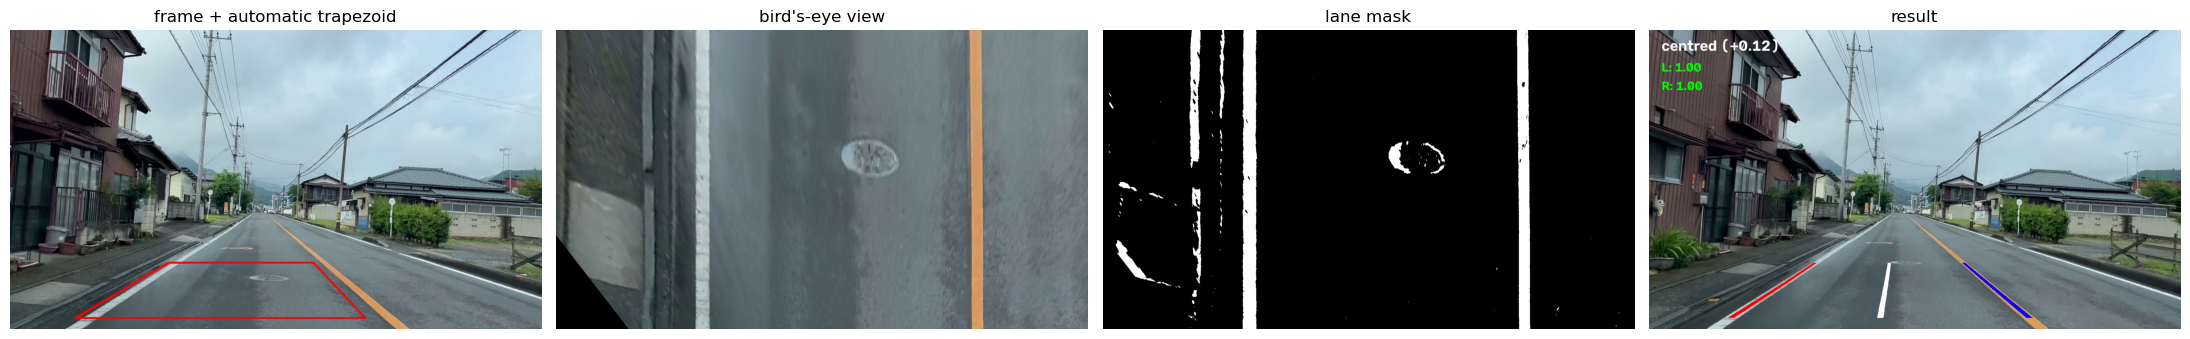

In [14]:
# read the original frame and the annotated frame from the middle of the video
source_video = cv2.VideoCapture(VIDEO_PATH)
frame_index = int(source_video.get(cv2.CAP_PROP_FRAME_COUNT)) // 2
source_video.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
original = source_video.read()[1]
annotated_video = cv2.VideoCapture(OUTPUT_PATH)
annotated_video.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
annotated = annotated_video.read()[1]

# panel 1: the original with the trapezoid drawn on it; panels 2 and 3: top view and its paint mask
frame_with_trapezoid = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)                      # Matplotlib expects RGB, OpenCV uses BGR
cv2.polylines(frame_with_trapezoid, [np.int32(trapezoid)], True, (255, 0, 0), max(2, frame_width // 300))
birdseye = cv2.warpPerspective(original, to_birdseye, (frame_width, frame_height))

panels = (frame_with_trapezoid, cv2.cvtColor(birdseye, cv2.COLOR_BGR2RGB),
          lane_marking_mask(birdseye), cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
titles = ("frame + automatic trapezoid", "bird's-eye view", "lane mask", "result")

figure, axes = plt.subplots(1, 4, figsize=(22, 4))
for axis, panel, title in zip(axes, panels, titles):
    axis.imshow(panel, cmap="gray")                                                   # the grey colour map only affects the mask panel
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.savefig("pipeline.png", dpi=100)
plt.show()

## 9. Operational Design Domain (ODD)

The ODD is the set of conditions in which the system can be trusted.

### Where it works

| Condition | What the system does | Why |
|---|---|---|
| Solid yellow line in daylight | Detected in almost every frame, confidence near 1 | Saturated colour, and a continuous line gives paint on every row 
| Dashed white line, straight or gently curved road | Detected most of the time, with low confidence | Only about a sixth to a third of the rows hold paint at once, but 10 % is enough to accept a fit 
| Changing light and moderate shadows | Mostly handled | Otsu thresholds are recomputed on every frame, and white paint only has to be brighter than its own row
| Gentle curves | Followed | A parabola fits the curve and the search band moves with the previous fit 
| Short gaps in the markings | Overlay stays in place, boundary shown grey and `UNCERTAIN`, position label orange, no jump | The old fit is kept and the search stays near it

### Where it degrades safely (the overlay says it is unsure)

| Condition | What the system does | Why 
|---|---|---
| Long gaps in dashes, faded or worn paint | Boundary `UNCERTAIN` and held at its last position, position label orange | Fewer than 10 % of rows have paint 
| Lane change in progress | Both boundaries `UNCERTAIN` and the overlay stays on the old lane; it should recover once the car is centred in the new lane | The boundaries leave the 0.5 m search band
| Merges, exits, widening or narrowing lane | Both fits rejected and held | The lane width leaves the 30 % tolerance 

### Where it fails or is unreliable 

| Condition | What happens | Why
|---|---|---|
| Bad start of the video: lane change, intersection, a boundary not visible in the first second | The trapezoid is wrong and every later frame is wrong, or the calibration stops with an error | The transform is computed once from the first second and never corrected
| Hills, braking, bumps, camera vibration | Top view is distorted, offset is biased, the fit can still look confident | The transform assumes a flat road and a fixed camera 
| Sharp curves | Boundary lost or cut short | The line leaves the 0.5 m band or the trapezoid, which stops halfway to the horizon 
| White or yellow objects in the lane: vehicles, arrows, crosswalks, stop lines, text | The fit can be pulled off the real boundary while confidence looks normal | They pass the paint mask, and the fit is plain least squares with no outlier rejection 
| Night, dusk, glare, tunnels, wet road with reflections | Missed paint or false paint | Reflections and glare look like bright paint, and low contrast hides real paint 